# Justice & Notary branch visits: where to investigate first

**Audience:** Tayseer service-operations director (with Ministry of Justice branch operations)
**Decision:** Which regions' in-person Justice & Notary service should be audited first?
**Scope:** `Justice & Notary`, channel `Branch`, all 13 regions, Jul 2021 – Jun 2026. Headline figures use the latest 12 months (Jul 2025 – Jun 2026).

**Metric:** `avg_completion_min` is an average per row, so every group figure is a **transaction-weighted mean**:
sum(avg_completion_min × transactions) / sum(transactions). `csat` is weighted the same way. Complaints are shown per 10,000 transactions.
`digital_adoption_pct` repeats across the four channels, so it is de-duplicated to one value per month × region × category before averaging.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Works locally and in Colab (upload the CSV or clone the repo first)
df = pd.read_csv("tayseer_services.csv", parse_dates=["month"])
print(df.shape)
print(df["month"].min().date(), "to", df["month"].max().date())
df.head()

(28080, 12)
2021-07-01 to 2026-06-01


,month,region,service_category,channel,transactions,unique_users,digital_adoption_pct,avg_completion_min,cost_per_txn_sar,csat,sla_met_pct,complaints
0,2021-07-01,Al-Baha,Business & Licensing,Branch,5727,4745,33.4,117.0,51.88,3.05,80.7,10
1,2021-07-01,Al-Baha,Business & Licensing,Call Center,2575,1708,33.4,31.5,24.11,3.57,93.2,2
2,2021-07-01,Al-Baha,Business & Licensing,Mobile App,1936,721,33.4,13.7,6.26,4.13,96.2,1
3,2021-07-01,Al-Baha,Business & Licensing,Web Portal,2425,1221,33.4,19.4,8.63,3.85,94.9,3
4,2021-07-01,Al-Baha,Education & Training,Branch,7443,5923,37.0,29.4,39.00,3.55,84.4,7


## 1. Helper: transaction-weighted mean

In [2]:
def wmean(d, col):
    return (d[col] * d["transactions"]).sum() / d["transactions"].sum()

SW = ["Al-Baha", "Asir", "Jazan", "Makkah", "Najran"]   # regions flagged in step 2
df["group"] = np.where(df["region"].isin(SW), "Southwest 5", "Other 8")

jn = df[df["service_category"] == "Justice & Notary"]
jn_branch = jn[jn["channel"] == "Branch"]
last12 = jn_branch[jn_branch["month"] >= "2025-07-01"]
print(last12["month"].nunique(), "months in the latest 12-month window")

12 months in the latest 12-month window


## 2. Compare regions (latest 12 months)

In [3]:
by_region = (last12.groupby("region")
             .apply(lambda d: pd.Series({
                 "branch_min": wmean(d, "avg_completion_min"),
                 "csat": wmean(d, "csat"),
                 "transactions": d["transactions"].sum()}), include_groups=False)
             .sort_values("branch_min"))
by_region.round(1)

,branch_min,csat,transactions
region,,,
Riyadh,45.4,3.5,437339.0
Qassim,45.9,3.2,78120.0
Eastern Province,46.6,3.5,254429.0
Northern Borders,50.4,3.6,21815.0
Hail,50.6,3.5,41318.0
Al-Jouf,50.9,3.5,31680.0
Madinah,52.7,3.6,129735.0
Tabuk,54.9,3.2,51156.0
Makkah,119.5,3.2,509135.0


In [4]:
summary = (last12.groupby("group")
           .apply(lambda d: pd.Series({
               "branch_min": wmean(d, "avg_completion_min"),
               "csat": wmean(d, "csat"),
               "complaints_per_10k": d["complaints"].sum() / d["transactions"].sum() * 1e4,
               "transactions": d["transactions"].sum()}), include_groups=False))
summary.round(2)

,branch_min,csat,complaints_per_10k,transactions
group,,,,
Other 8,47.59,3.50,11.19,1045592.0
Southwest 5,122.90,3.18,13.40,847990.0


## 3. Is it the region or the branch? Same service, all channels (latest 12 months)

In [5]:
jn12 = jn[jn["month"] >= "2025-07-01"]
by_channel = (jn12.groupby(["channel", "group"])
              .apply(lambda d: wmean(d, "avg_completion_min"), include_groups=False)
              .unstack().round(1))
by_channel["ratio"] = (by_channel["Southwest 5"] / by_channel["Other 8"]).round(2)
by_channel

group,Other 8,Southwest 5,ratio
channel,,,
Branch,47.6,122.9,2.58
Call Center,29.8,32.9,1.10
Mobile App,10.5,11.3,1.08
Web Portal,15.8,17.6,1.11


In [6]:
# Digital adoption: de-duplicate the 4 channel rows first, then simple mean of months
adopt = (jn12.drop_duplicates(["month", "region", "service_category"])
         .groupby("group")["digital_adoption_pct"].mean().round(1))
adopt

group
Other 8        61.5
Southwest 5    52.7
Name: digital_adoption_pct, dtype: float64

## 4. Change over time (monthly)

In [7]:
monthly = (jn_branch.groupby(["month", "group"])
           .apply(lambda d: wmean(d, "avg_completion_min"), include_groups=False)
           .unstack())
monthly["ratio"] = monthly["Southwest 5"] / monthly["Other 8"]
print("Ratio SW5 / Other8, min–max:", monthly["ratio"].min().round(2), "–", monthly["ratio"].max().round(2))
first12 = jn_branch[jn_branch["month"] < "2022-07-01"].groupby("group").apply(
    lambda d: wmean(d, "avg_completion_min"), include_groups=False)
print("First 12 months (Jul 2021–Jun 2022):"); print(first12.round(1))

Ratio SW5 / Other8, min–max: 2.03 – 3.13
First 12 months (Jul 2021–Jun 2022):
group
Other 8         56.7
Southwest 5    139.7
dtype: float64


## 5. Charts

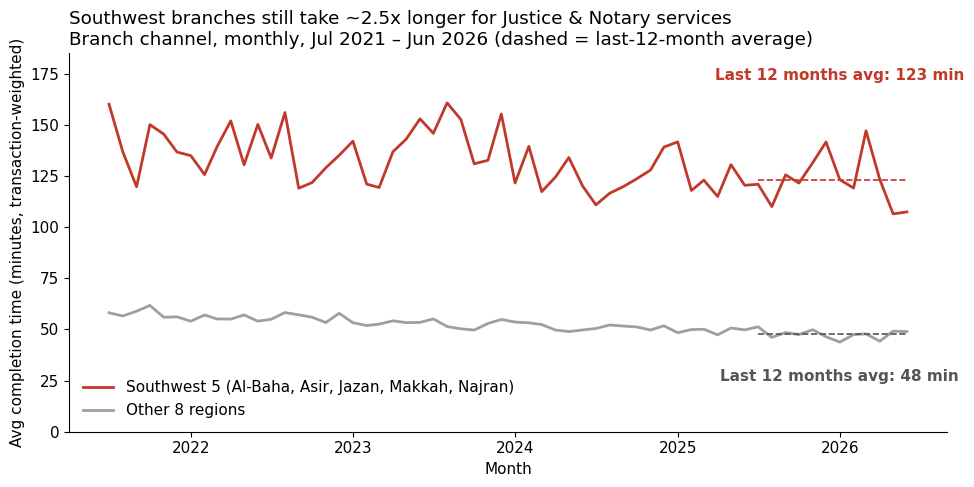

In [8]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
HI, GREY = "#C0392B", "#9AA0A6"

# Chart 1: change over time
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index, monthly["Southwest 5"], color=HI, lw=2, label="Southwest 5 (Al-Baha, Asir, Jazan, Makkah, Najran)")
ax.plot(monthly.index, monthly["Other 8"], color=GREY, lw=2, label="Other 8 regions")
ax.set_ylabel("Avg completion time (minutes, transaction-weighted)")
ax.set_xlabel("Month")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
s, o = summary.loc["Southwest 5", "branch_min"], summary.loc["Other 8", "branch_min"]
win = monthly.index[monthly.index >= "2025-07-01"]
ax.hlines(s, win[0], win[-1], colors=HI, linestyles="--", lw=1.2)
ax.hlines(o, win[0], win[-1], colors="#555", linestyles="--", lw=1.2)
ax.text(win[len(win)//2], 172, f"Last 12 months avg: {s:.0f} min", color=HI, ha="center", fontweight="bold")
ax.text(win[len(win)//2], 25, f"Last 12 months avg: {o:.0f} min", color="#555", ha="center", fontweight="bold")
ax.set_ylim(0, 185)
ax.set_title("Southwest branches still take ~2.5x longer for Justice & Notary services\n"
             "Branch channel, monthly, Jul 2021 – Jun 2026 (dashed = last-12-month average)", loc="left")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("chart1_trend.png", dpi=150)
plt.show()

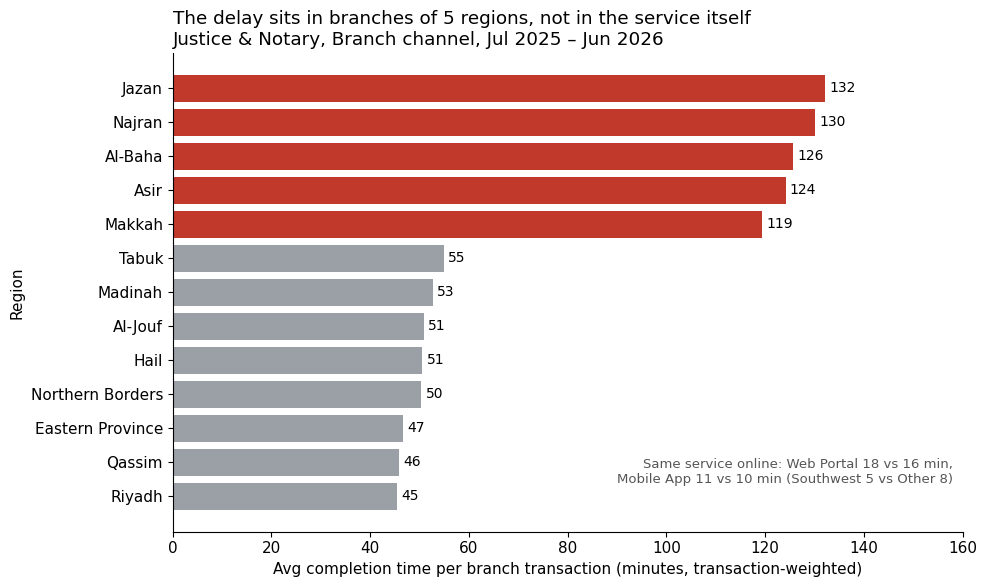

In [9]:
# Chart 2: compare regions
fig, ax = plt.subplots(figsize=(10, 6))
colors = [HI if r in SW else GREY for r in by_region.index]
bars = ax.barh(by_region.index, by_region["branch_min"], color=colors)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=10)
ax.set_xlim(0, 160)
ax.set_xlabel("Avg completion time per branch transaction (minutes, transaction-weighted)")
ax.set_ylabel("Region")
bc = by_channel
ax.text(158, 0.3, f"Same service online: Web Portal {bc.loc['Web Portal','Southwest 5']:.0f} vs {bc.loc['Web Portal','Other 8']:.0f} min,\n"
        f"Mobile App {bc.loc['Mobile App','Southwest 5']:.0f} vs {bc.loc['Mobile App','Other 8']:.0f} min (Southwest 5 vs Other 8)",
        ha="right", va="bottom", fontsize=9.5, color="#555")
ax.set_title("The delay sits in branches of 5 regions, not in the service itself\n"
             "Justice & Notary, Branch channel, Jul 2025 – Jun 2026", loc="left")
fig.tight_layout()
fig.savefig("chart2_regions.png", dpi=150)
plt.show()

## 6. Sanity checks
- Row grain: one row per month × region × category × channel (checked below).
- Transaction-weighted vs simple mean give the same ranking.

In [10]:
assert not df.duplicated(["month", "region", "service_category", "channel"]).any()
simple = last12.groupby("region")["avg_completion_min"].mean().sort_values()
print("Top 5 by simple mean:", list(simple.index[-5:]))
print("Top 5 by weighted mean:", list(by_region.index[-5:]))

Top 5 by simple mean: ['Makkah', 'Asir', 'Al-Baha', 'Najran', 'Jazan']
Top 5 by weighted mean: ['Makkah', 'Asir', 'Al-Baha', 'Najran', 'Jazan']
